q-> expectation : need a clarity on who is spending more money for shopping incase of gender,age group,state,occuoation ,product category and marital status

 or   consider sales dataset and analyse it in proper way

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("https://github.com/Kalai865/Data_Analysis-Datasets/raw/refs/heads/main/sales_data.csv",encoding='iso-8859-1')
df

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0,NaN,NaN
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0,NaN,NaN
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0,NaN,NaN
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0,NaN,NaN
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11246,1000695,Manning,P00296942,M,18-25,19,1,Maharashtra,Western,Chemical,Office,4,370.0,NaN,NaN
11247,1004089,Reichenbach,P00171342,M,26-35,33,0,Haryana,Northern,Healthcare,Veterinary,3,367.0,NaN,NaN
11248,1001209,Oshin,P00201342,F,36-45,40,0,Madhya Pradesh,Central,Textile,Office,4,213.0,NaN,NaN
11249,1004023,Noonan,P00059442,M,36-45,37,0,Karnataka,Southern,Agriculture,Office,3,206.0,NaN,NaN


In [3]:
# blikto applications lets consider

In [5]:
# exloration
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11251 entries, 0 to 11250
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11251 non-null  int64  
 1   Cust_name         11251 non-null  object 
 2   Product_ID        11251 non-null  object 
 3   Gender            11251 non-null  object 
 4   Age Group         11251 non-null  object 
 5   Age               11251 non-null  int64  
 6   Marital_Status    11251 non-null  int64  
 7   State             11251 non-null  object 
 8   Zone              11251 non-null  object 
 9   Occupation        11251 non-null  object 
 10  Product_Category  11251 non-null  object 
 11  Orders            11251 non-null  int64  
 12  Amount            11239 non-null  float64
 13  Status            0 non-null      float64
 14  unnamed1          0 non-null      float64
dtypes: float64(3), int64(4), object(8)
memory usage: 1.3+ MB


In [6]:
# checking null
df['Amount'].isnull().sum()

np.int64(12)

In [7]:
# droping the unwanted columns  (unnamed1 Status )-->everything is nan in this
df=df.drop(['unnamed1','Status'],axis=1)

In [8]:
df.columns

Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age',
       'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category',
       'Orders', 'Amount'],
      dtype='object')

In [9]:
# dropinf all the nan value
df.dropna(inplace=True)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11239 entries, 0 to 11250
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11239 non-null  int64  
 1   Cust_name         11239 non-null  object 
 2   Product_ID        11239 non-null  object 
 3   Gender            11239 non-null  object 
 4   Age Group         11239 non-null  object 
 5   Age               11239 non-null  int64  
 6   Marital_Status    11239 non-null  int64  
 7   State             11239 non-null  object 
 8   Zone              11239 non-null  object 
 9   Occupation        11239 non-null  object 
 10  Product_Category  11239 non-null  object 
 11  Orders            11239 non-null  int64  
 12  Amount            11239 non-null  float64
dtypes: float64(1), int64(4), object(8)
memory usage: 1.2+ MB


In [11]:
df

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11246,1000695,Manning,P00296942,M,18-25,19,1,Maharashtra,Western,Chemical,Office,4,370.0
11247,1004089,Reichenbach,P00171342,M,26-35,33,0,Haryana,Northern,Healthcare,Veterinary,3,367.0
11248,1001209,Oshin,P00201342,F,36-45,40,0,Madhya Pradesh,Central,Textile,Office,4,213.0
11249,1004023,Noonan,P00059442,M,36-45,37,0,Karnataka,Southern,Agriculture,Office,3,206.0


In [12]:
## 3rd step
#  want to change f=female and m=male
d={'F':'Female','M':'Male'}
df["Gender"]=df["Gender"].map(d)
df["Gender"].unique()

array(['Female', 'Male'], dtype=object)

In [13]:
# want to change marital status --->0 to single and 1 to married
df["Marital_Status"]=df["Marital_Status"].map({0:"Single",1:"Married"})
df["Marital_Status"].unique()

array(['Single', 'Married'], dtype=object)

In [14]:
df #checking the name change

,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount
0,1002903,Sanskriti,P00125942,Female,26-35,28,Single,Maharashtra,Western,Healthcare,Auto,1,23952.0
1,1000732,Kartik,P00110942,Female,26-35,35,Married,Andhra Pradesh,Southern,Govt,Auto,3,23934.0
2,1001990,Bindu,P00118542,Female,26-35,35,Married,Uttar Pradesh,Central,Automobile,Auto,3,23924.0
3,1001425,Sudevi,P00237842,Male,0-17,16,Single,Karnataka,Southern,Construction,Auto,2,23912.0
4,1000588,Joni,P00057942,Male,26-35,28,Married,Gujarat,Western,Food Processing,Auto,2,23877.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11246,1000695,Manning,P00296942,Male,18-25,19,Married,Maharashtra,Western,Chemical,Office,4,370.0
11247,1004089,Reichenbach,P00171342,Male,26-35,33,Single,Haryana,Northern,Healthcare,Veterinary,3,367.0
11248,1001209,Oshin,P00201342,Female,36-45,40,Single,Madhya Pradesh,Central,Textile,Office,4,213.0
11249,1004023,Noonan,P00059442,Male,36-45,37,Single,Karnataka,Southern,Agriculture,Office,3,206.0


In [15]:
# checking duplicated
df.duplicated().sum()

np.int64(8)

In [16]:
# drop duplicated values
df.drop_duplicates(inplace=True)

In [17]:
# checking duplicated  again
df.duplicated().sum()

np.int64(0)

In [18]:
# now we have cleaned data set

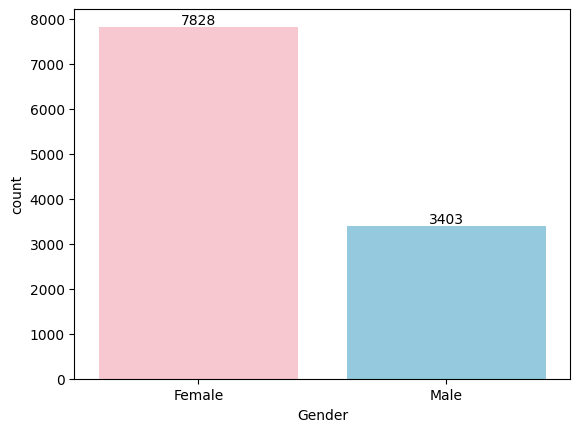

In [19]:
# visualization by seaborn
# the count of males and females based on gender col

g =sns.countplot(x="Gender",data=df,hue="Gender",palette=["pink","skyblue"])
for i in g.containers:
  g.bar_label(i)
plt.show()
# with this i can analyse the females are spending more in the website

In [20]:
# how much money they speds
# total ammnt spend my males and femles

In [21]:
# now based on gender we need to gropuby
G=df.groupby("Gender")["Amount"].sum()
G

,Amount
Gender,
Female,74307682.43
Male,31871146.00


In [22]:
# converting the dataframe
G=pd.DataFrame(G)
G

,Amount
Gender,
Female,74307682.43
Male,31871146.00


<Axes: xlabel='Gender', ylabel='Amount'>

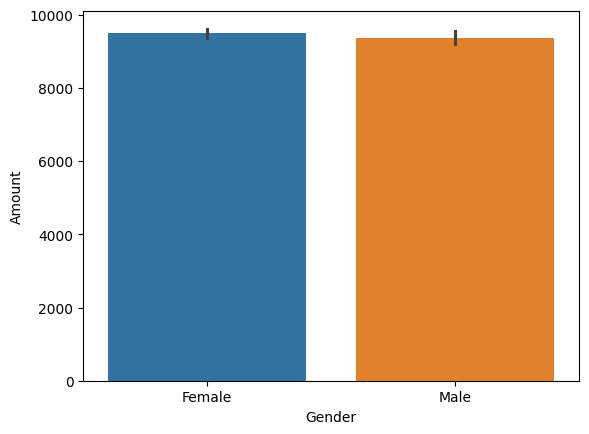

In [23]:
# visualze male and female ammount
# nbarplot
sns.barplot(x="Gender",y="Amount",data=df,hue="Gender")

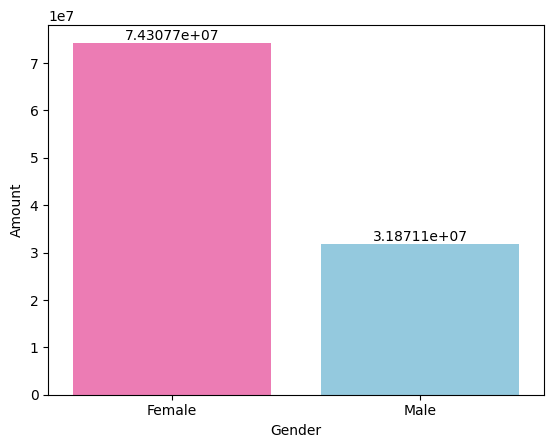

In [24]:
g=sns.barplot(x="Gender",y="Amount",data=G,palette=["hotpink","skyblue"],hue="Gender",errorbar=None)
for i in g.containers:
  g.bar_label(i)
plt.show()

In [25]:
df.columns

Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age',
       'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category',
       'Orders', 'Amount'],
      dtype='object')

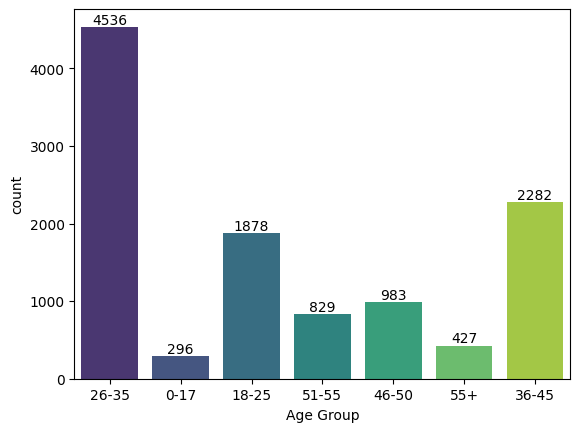

In [26]:
# visulaize count incase of age group
# count based on age group
a=sns.countplot(x="Age Group",data=df,hue="Age Group",palette="viridis")
for i in a.containers:
  a.bar_label(i)
plt.show()

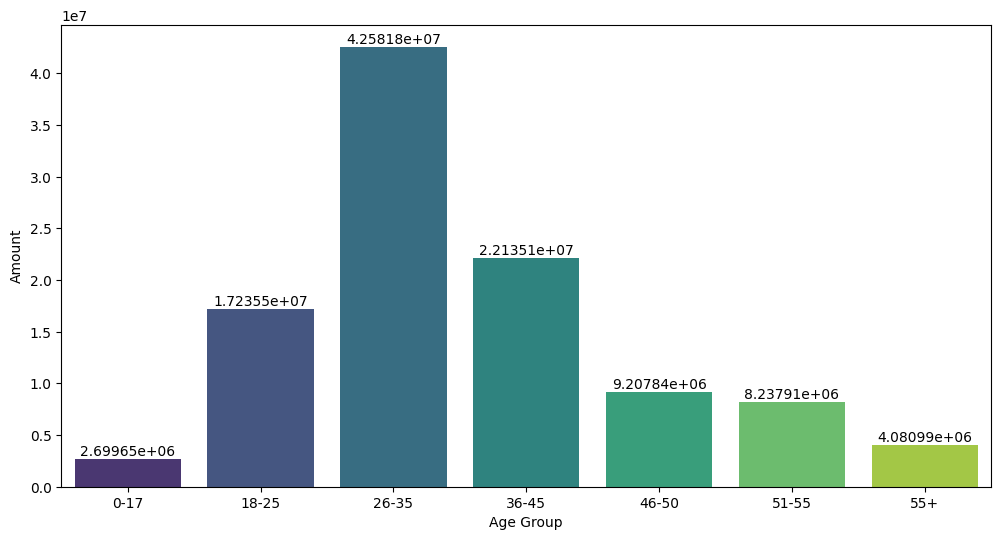

In [42]:
# groupby age group
G=df.groupby("Age Group")["Amount"].sum()
G=pd.DataFrame(G)
G

# barpl0t
plt.figure(figsize=(12,6))
a=sns.barplot(x="Age Group",y="Amount",data=G,hue="Age Group",errorbar=None,palette="viridis")
for i in a.containers:
  a.bar_label(i)
plt.show()

In [28]:
df.columns

Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age',
       'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category',
       'Orders', 'Amount'],
      dtype='object')

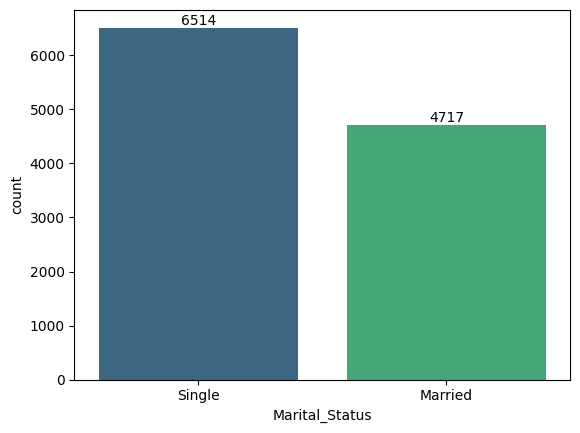

In [29]:
# who is spending more incase of marital status
# count based on marital_status
a=sns.countplot(x="Marital_Status",data=df,hue="Marital_Status",palette="viridis")
for i in a.containers:
  a.bar_label(i)
plt.show()


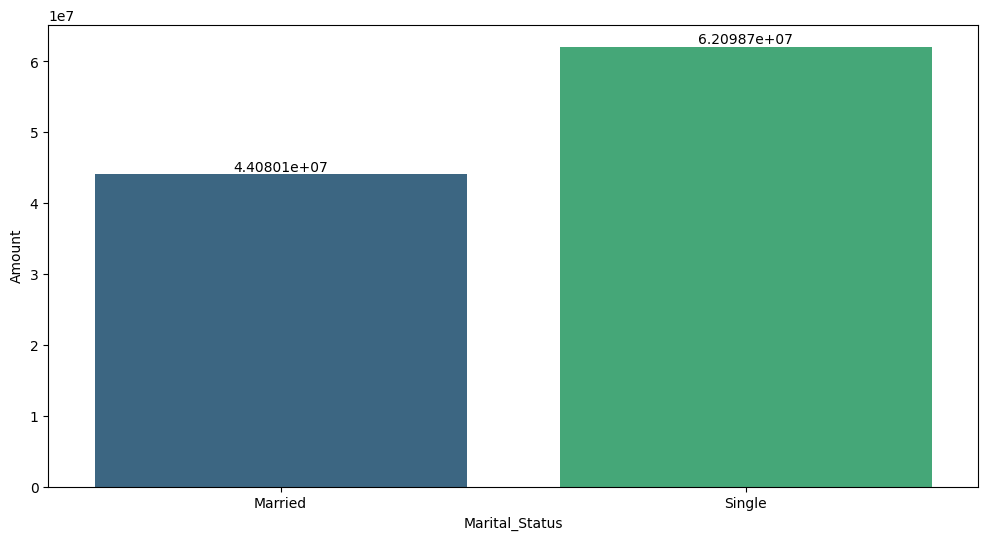

In [30]:
# how much they are spending
m=df.groupby("Marital_Status")["Amount"].sum()
m=pd.DataFrame(m)

plt.figure(figsize=(12,6))
a=sns.barplot(x="Marital_Status",y="Amount",data=m,hue="Marital_Status",errorbar=None,palette="viridis")
for i in a.containers:
  a.bar_label(i)
plt.show()

In [43]:
df.columns

Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age',
       'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category',
       'Orders', 'Amount'],
      dtype='object')

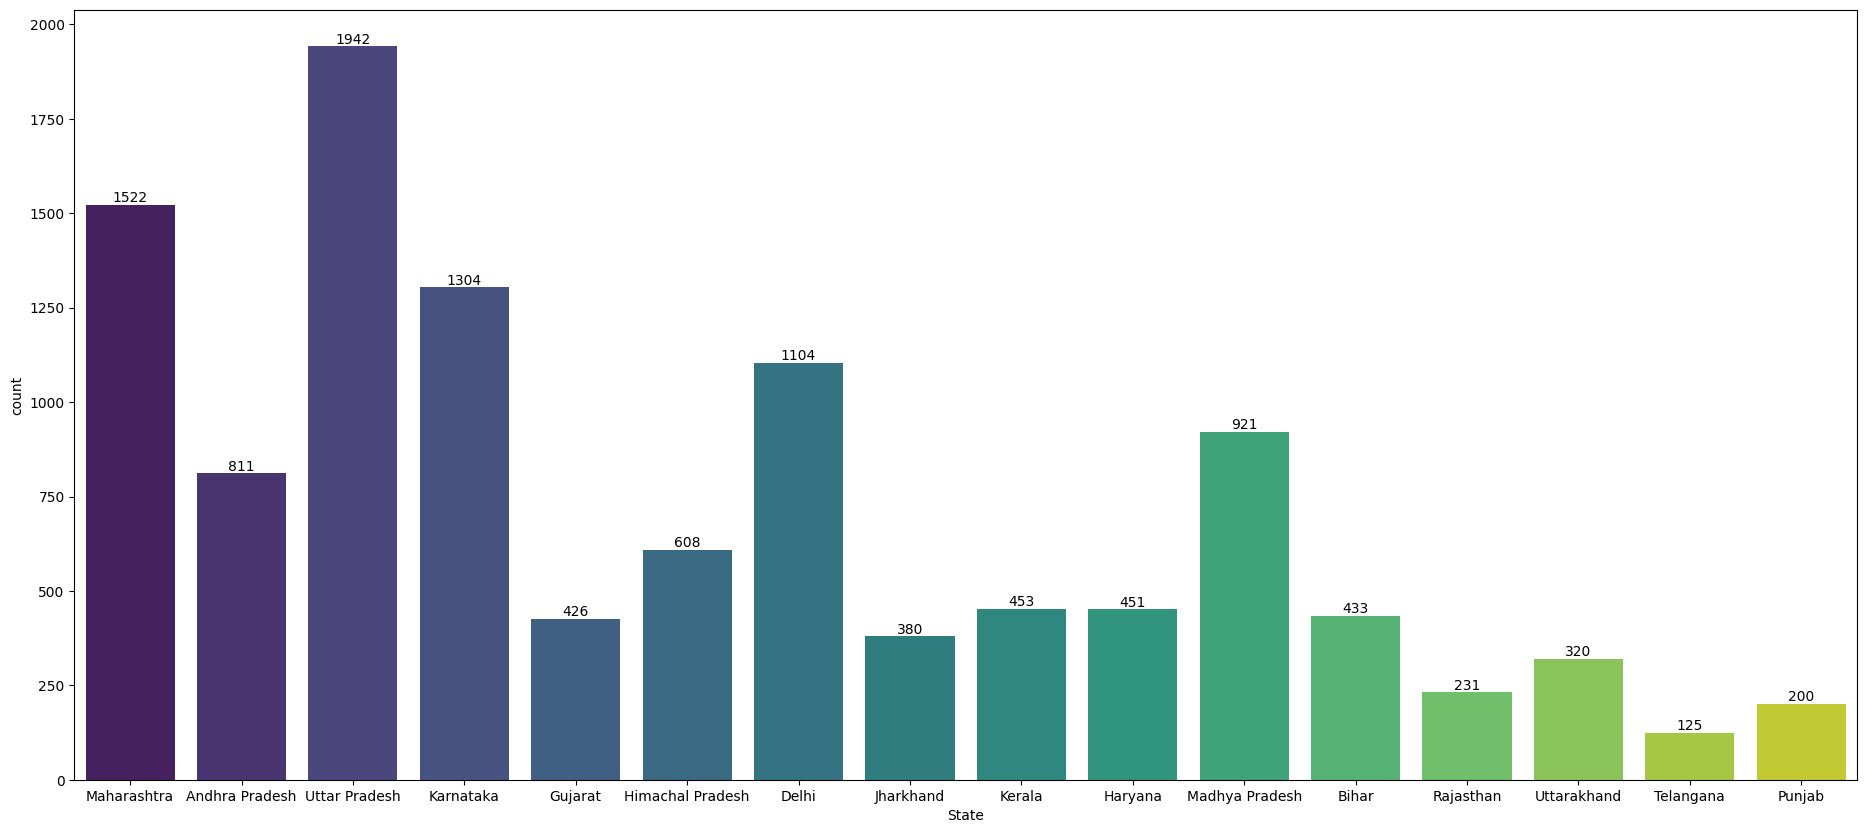

In [31]:
# who is spending more incase of states
# count based on states
plt.figure(figsize=(23,10))
a=sns.countplot(x="State",data=df,hue="State",palette="viridis")
for i in a.containers:
  a.bar_label(i)
plt.show()

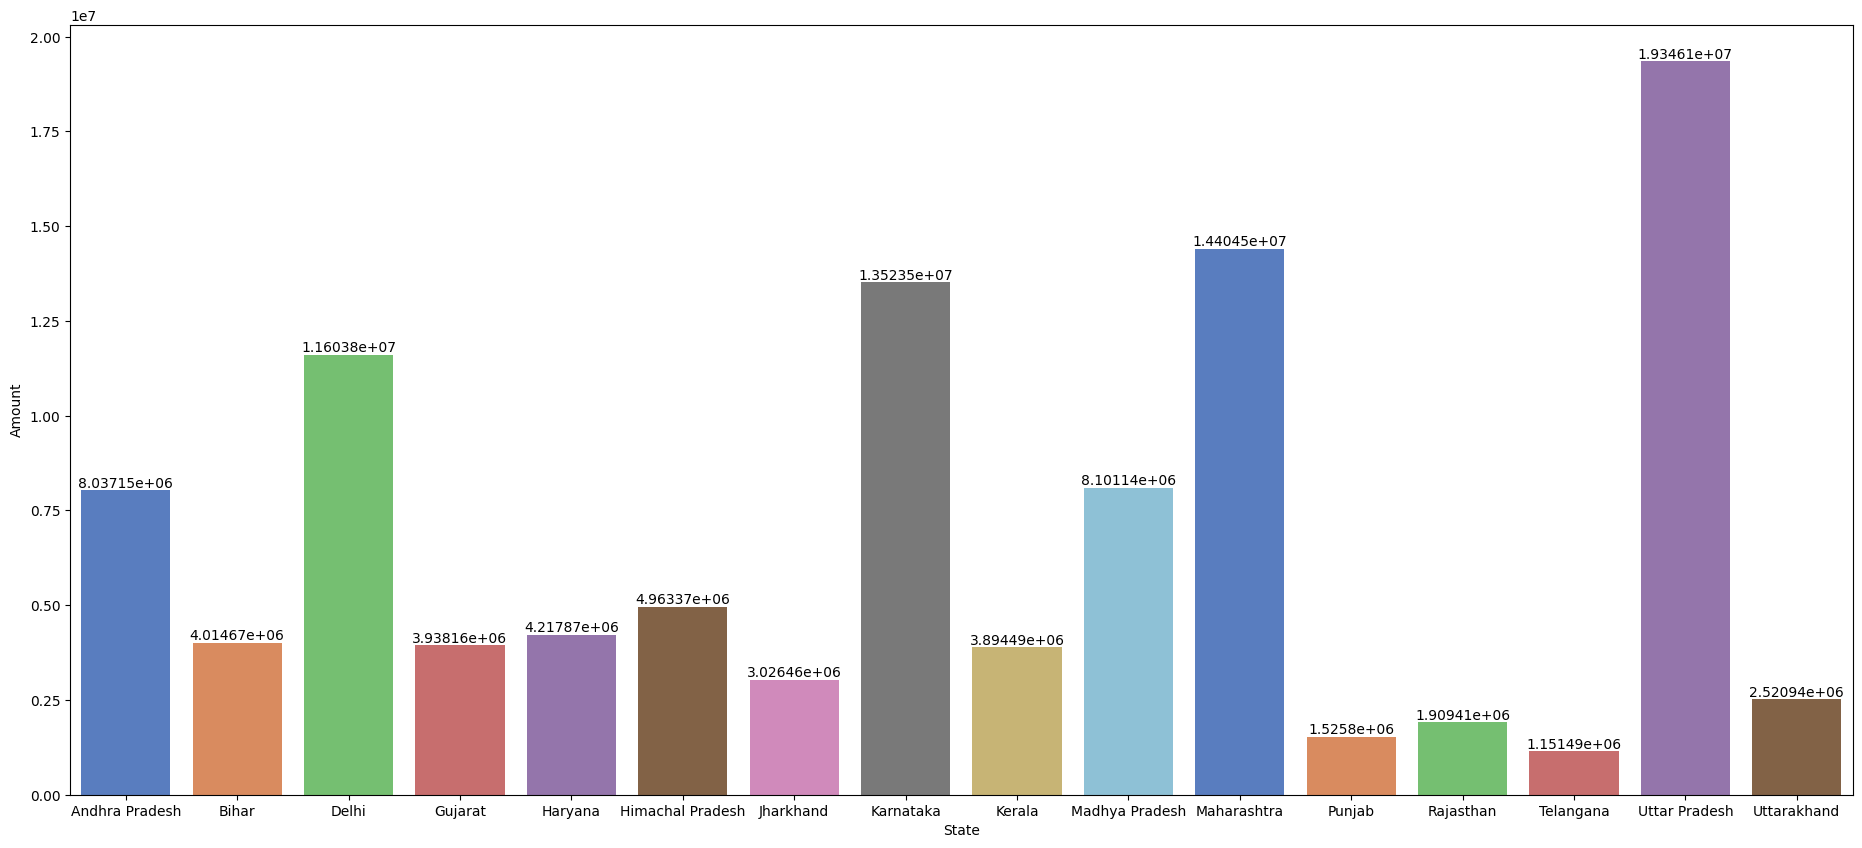

In [32]:
# how much they are spending
m=df.groupby("State")["Amount"].sum()
m=pd.DataFrame(m)

plt.figure(figsize=(23,10))
a=sns.barplot(x="State",y="Amount",data=m,hue="State",errorbar=None,palette="muted")
for i in a.containers:
  a.bar_label(i)
plt.show()

In [33]:
df.columns

Index(['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age',
       'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category',
       'Orders', 'Amount'],
      dtype='object')

In [34]:
df['Occupation'].unique()

array(['Healthcare', 'Govt', 'Automobile', 'Construction',
       'Food Processing', 'Lawyer', 'Media', 'Banking', 'Retail',
       'IT Sector', 'Aviation', 'Hospitality', 'Agriculture', 'Textile',
       'Chemical'], dtype=object)

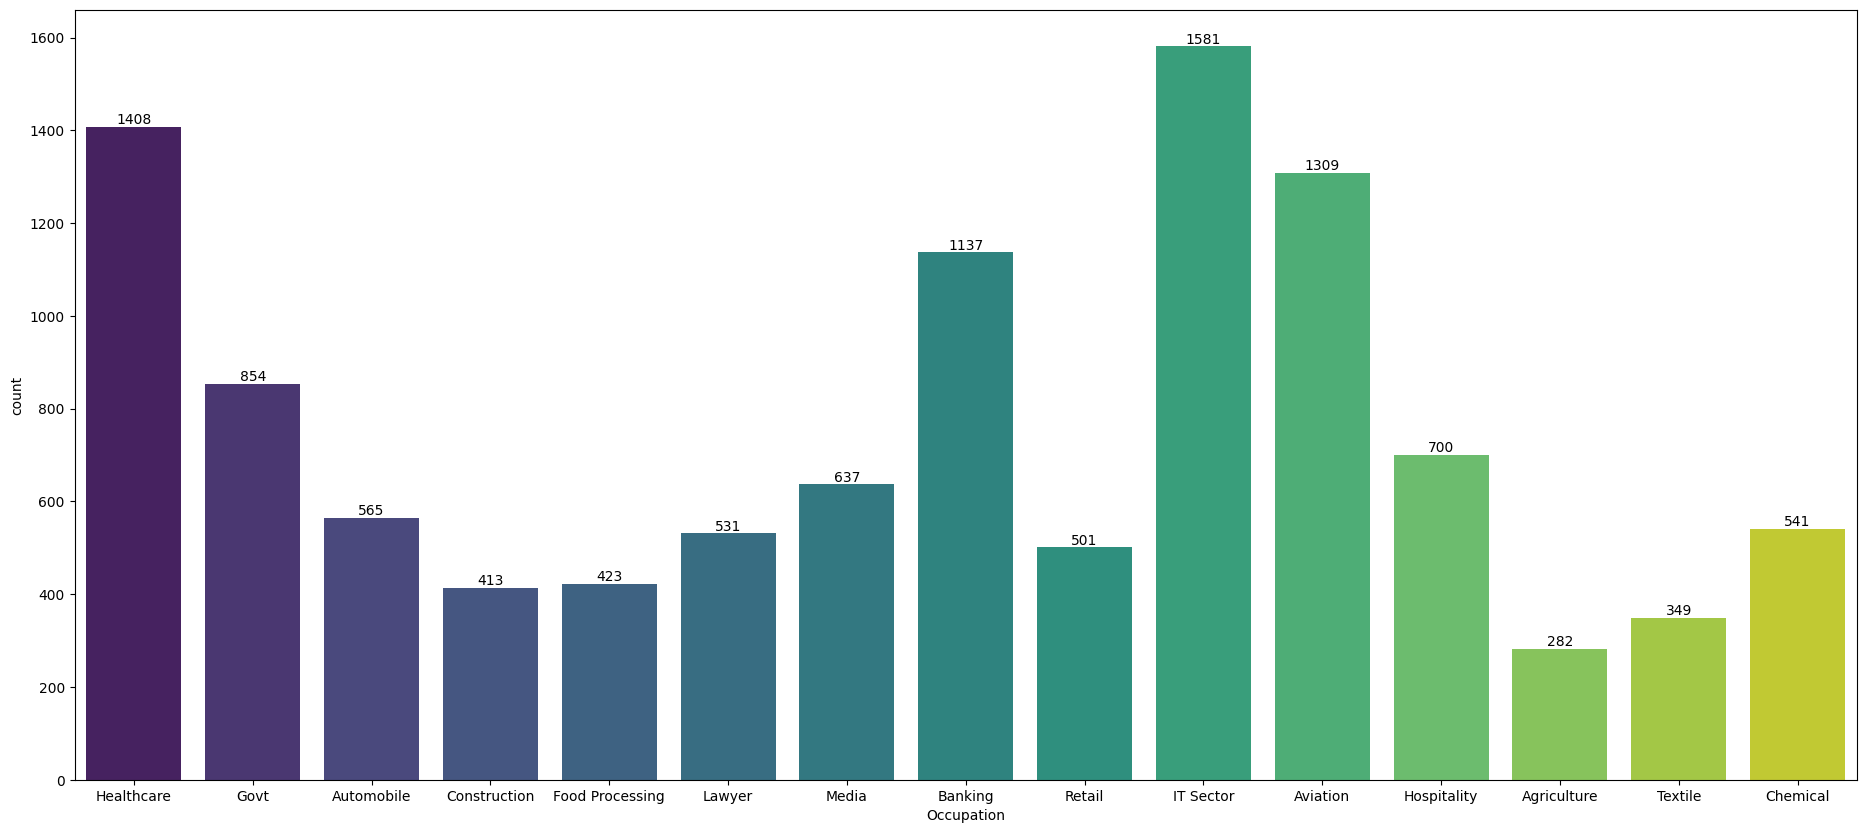

In [35]:
# who is spending more incase of occuoation
# count based on occupations
plt.figure(figsize=(23,10))
a=sns.countplot(x='Occupation',data=df,hue='Occupation',palette="viridis")
for i in a.containers:
  a.bar_label(i)
plt.show()

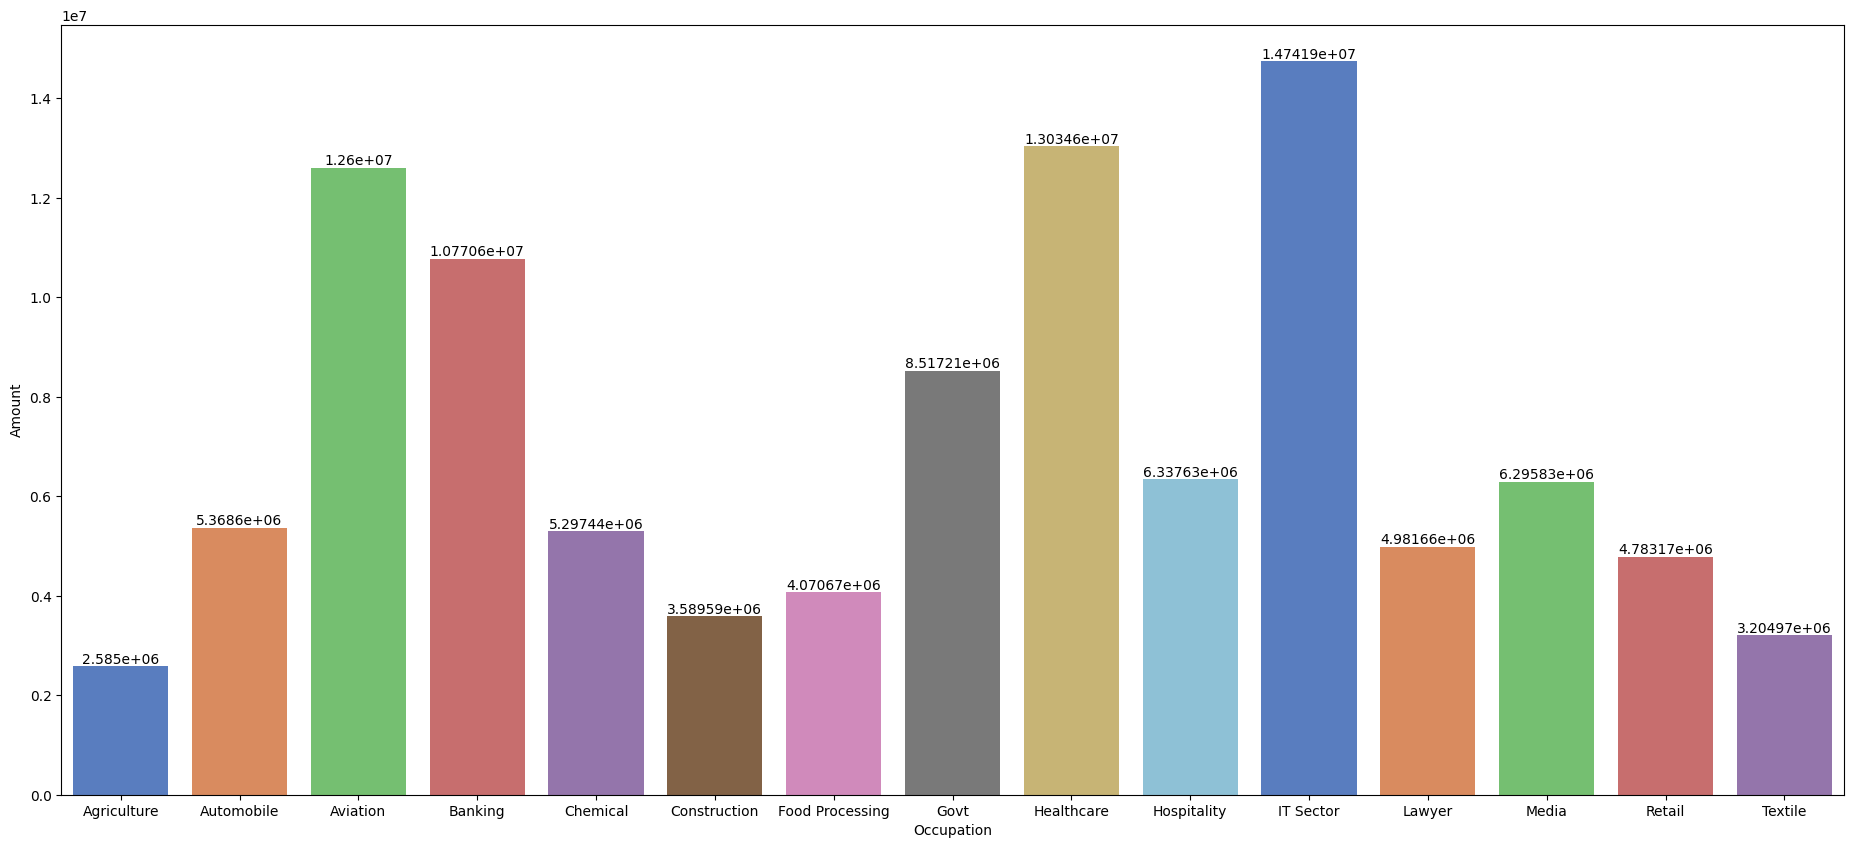

In [36]:
# how much they are spending
m=df.groupby('Occupation')["Amount"].sum()
m=pd.DataFrame(m)

plt.figure(figsize=(23,10))
a=sns.barplot(x='Occupation',y="Amount",data=m,hue='Occupation',errorbar=None,palette="muted")
for i in a.containers:
  a.bar_label(i)
plt.show()

In [37]:
# according to this analysis i can say that the

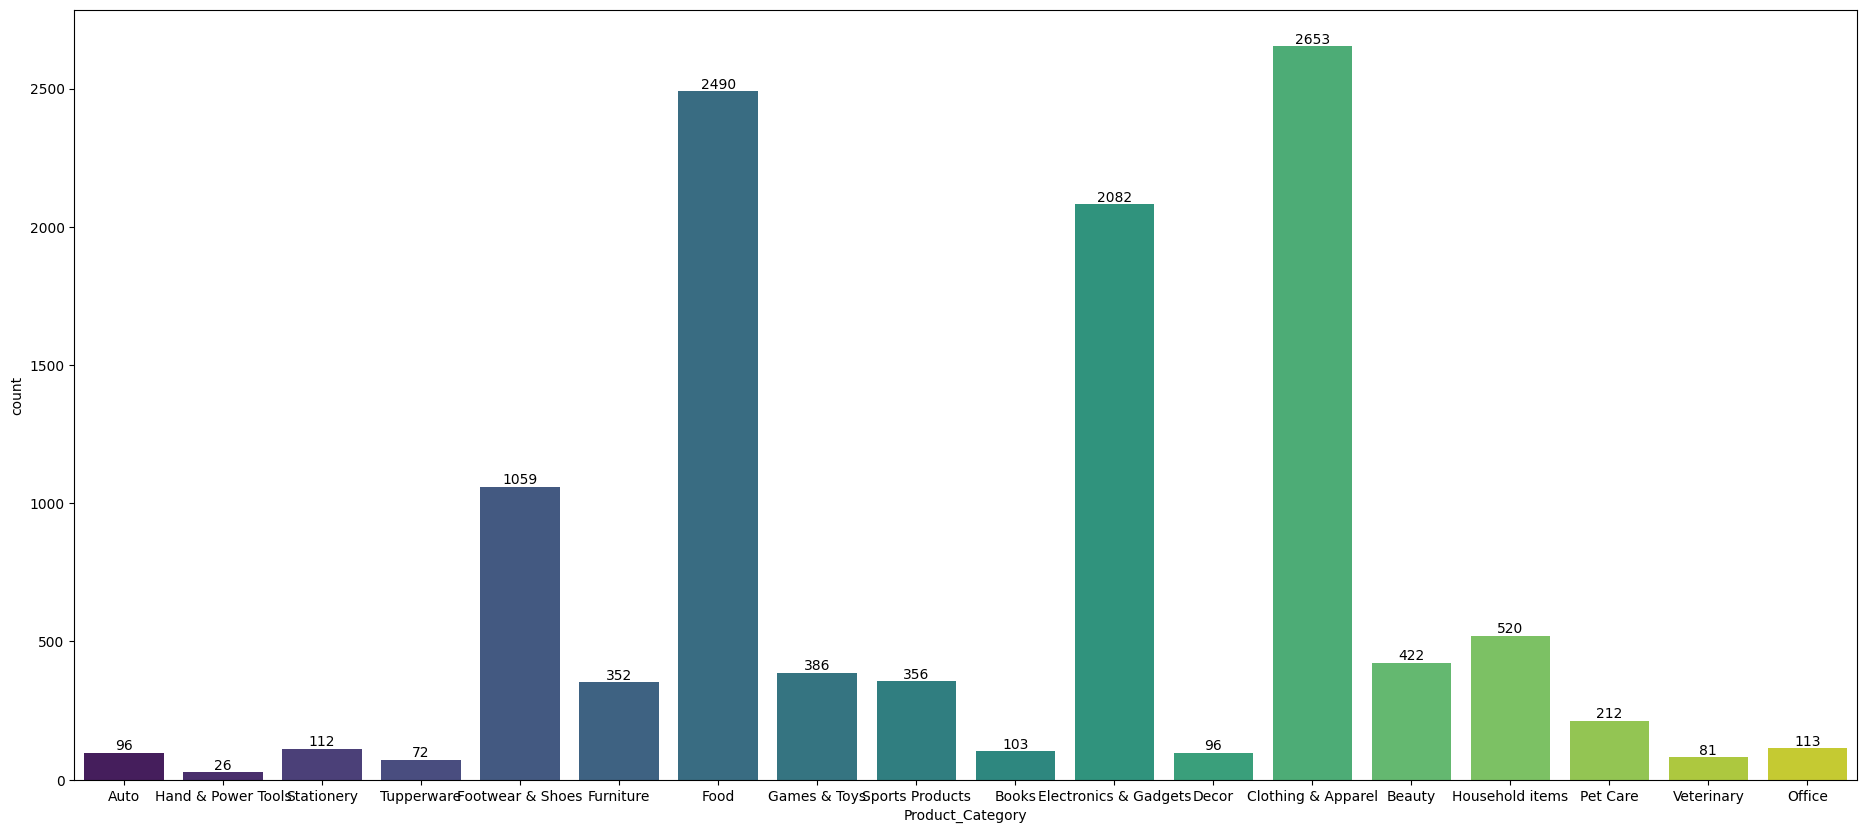

In [38]:
# which kind of product they are ordering (producti cat)
# no of orders
# count based on product category
plt.figure(figsize=(23,10))
a=sns.countplot(x='Product_Category',data=df,hue='Product_Category',palette="viridis")
for i in a.containers:
  a.bar_label(i)
plt.show()

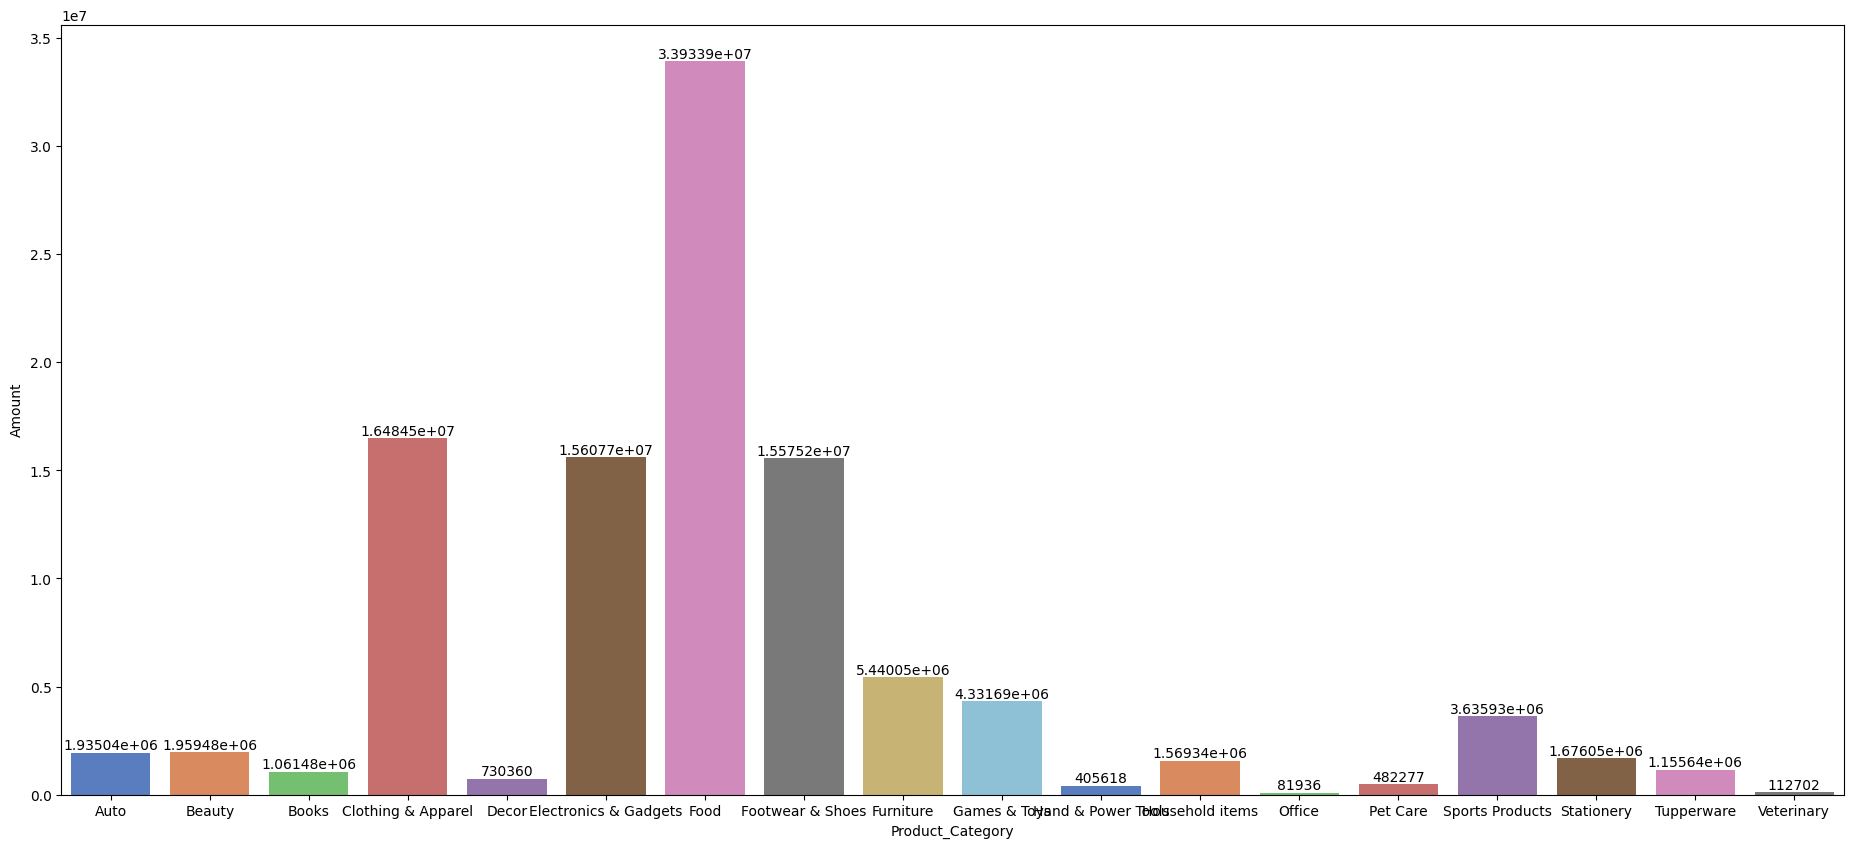

In [39]:
# how much they are spending
m=df.groupby('Product_Category')["Amount"].sum()
m=pd.DataFrame(m)

plt.figure(figsize=(23,10))
a=sns.barplot(x='Product_Category',y="Amount",data=m,hue='Product_Category',errorbar=None,palette="muted")
for i in a.containers:
  a.bar_label(i)
plt.show()

In [40]:
# conclusion as a data anayst
# conclusion:  based on above analysis i
# can conclude that single females of
# age group 26 to 35 from uttar pradesh, karnataka,maharashtra,
# working in it sector , aviation,and healthcare are spending more money
# on food , electronics and cloths


conclusion as a data anayst
conclusion:  based on above analysis i
can conclude that single females of
age group 26 to 35 from uttar pradesh, karnataka,maharashtra,
working in it sector , aviation,and healthcare are spending more money on food , electronics and cloths  
